In [2]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from scipy.stats import t
from matplotlib import pyplot as plt
import seaborn as sns

In [1]:
def func_1(x, a, b):
    return a * x ** b

In [3]:
def fitting(X, Y):
    popt, pcov = curve_fit(func_1, X, Y)
    a, b = popt
    y_pred = func_1(X, a, b)
    r2 = r2_score(Y, y_pred)
    x_sim = np.linspace(min(X), max(X), 100)
    y_sim = func_1(x_sim, a, b)

    return a, b, r2, x_sim, y_sim

In [ ]:
DF_1 = pd.read_csv('../main-results/extraction-area-relationship.csv')

X = DF_1['E (Mt)'].values
Y = DF_1['A (ha)'].values
a, b, r2, x_sim, y_sim = fitting(X, Y)

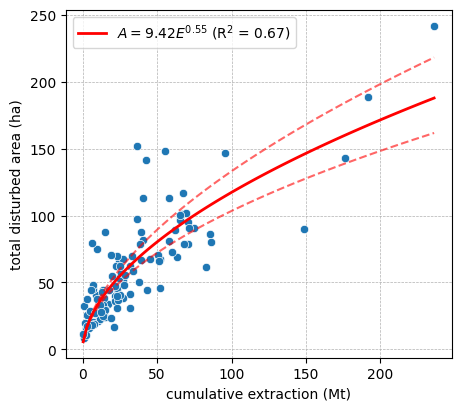

In [8]:
fig = plt.figure(figsize=(4.5, 4), constrained_layout=True)

ax1 = plt.subplot(1, 1, 1)
sns.scatterplot(x=X, y=Y, zorder=3)
ax1.plot(x_sim, y_sim, lw=2.0, color='r', label=f'$A={a:.2f}E^{{{b:.2f}}}$ (R$^{2}$ = {round(r2, 2)})', zorder=5)
ax1.plot(x_sim, func_1(x_sim, a, b*0.95), ls='--', c='r', alpha=0.6, zorder=5)
ax1.plot(x_sim, func_1(x_sim, a, b*1.05), ls='--', c='r', alpha=0.6, zorder=5)
ax1.grid('on', ls='--', lw=0.5)
ax1.legend(loc='best', fontsize=10)
ax1.set(xlabel='cumulative extraction (Mt)', ylabel='total disturbed area (ha)')

plt.show()